In [1]:
import importlib
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, roc_curve, auc, confusion_matrix, ConfusionMatrixDisplay
import numpy as np
from torch import load
import time
from h5py import File

In [2]:
import sys
from pathlib import Path

project_root = Path("..").resolve()  # points to /project
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from functions_library import *

In [3]:
#importlib.reload(data_loading)
#importlib.reload(model_training)
#importlib.reload(dataset_classes)
#importlib.reload(misc_functions)
#importlib.reload(curve_fitting)
#importlib.reload(training_classes)
#importlib.reload(neural_models)

In [4]:
device = torch.device('cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu')
model_library_path = "C:/Users/jonas/Coding/Master/Main/Masters_project/models_library/"
z_mass_hist_path = "C:/Users/jonas/Coding/Master/Main/csv_files/"
z_mass_files = ["Z_mass_EGAM1.csv", "Z_mass_EGAM7.csv"]
full_z_mass_hist_path = [z_mass_hist_path + file for file in z_mass_files]

In [5]:
base_string = "C:/Users/jonas/Coding/Master/Main/h5/"
data_strings = ["MC_EGAM1", "MC_EGAM7", "DATA_EGAM"]
name_strings = data_strings + ["MC_EGAM"]
full_strings = [base_string + data_string for data_string in data_strings]
h5_files_dir = data_loading.create_path_lists(full_strings, outputs=name_strings, mixing_list = [(0, 1)], seed=0)
h5_files_egam = h5_files_dir[name_strings[-1]]
h5_files_data = h5_files_dir[name_strings[-2]]

In [6]:
model_particle_size = []
model_names = ["origin", "pt", "eta", "phi", "e"]
for name in model_names:
    if name == "origin":
        small_dataset = dataset_classes.ZPairDataset(
            h5_files_egam[0],
            exclude_features = ["truth"],
            exclude_fields = {"egammas" : ["truthOrigin", "truthType", "passid_VeryLoose", "passid_Loose", "passid_Medium", "passid_Tight"]},
        )
    else:
        small_dataset = dataset_classes.ZPairDataset(
            h5_files_egam[0],
            exclude_features = ["truth"],
            exclude_fields = {"egammas" : ["truthOrigin", "truthType", name]},
        )
    particle_fields = [field for field in small_dataset.fields if not field.startswith("eventwise_")]
    event_fields = [field for field in small_dataset.fields if field.startswith("eventwise_")]
    model_particle_size.append(len(particle_fields) // 2)
    if len(particle_fields) % 2 != 0:
        raise ValueError("Pair particle fields are not evenly split between the two particles.")


In [7]:
device = torch.device('cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu')
bins = np.arange(55.05, 135.05, 0.1)
model_paths = [model_library_path + "model_" + name + "_pair.pth" for name in model_names]
models = {}
for name, path, size in zip(model_names, model_paths, model_particle_size):
    print(f"Loading model {name} from {path}")
    if name == "origin":
        output_size = 1
    else:
        output_size = 4
    model = neural_models.ParticlePairNetwork(
        size,
        len(event_fields),
        particle_hidden_sizes=[1024, 256, 256, 256, 256, 256, 64, 8],
        event_hidden_sizes=[64, 64, 16, 4],
        consolidation_hidden_sizes=[32, 32, 32, 8],
        output_size=output_size,
    ).to(device)
    model.load_state_dict(torch.load(path))
    model.eval()
    models[name] = model


Loading model origin from C:/Users/jonas/Coding/Master/Main/Masters_project/models_library/model_origin_pair.pth
Loading model pt from C:/Users/jonas/Coding/Master/Main/Masters_project/models_library/model_pt_pair.pth
Loading model eta from C:/Users/jonas/Coding/Master/Main/Masters_project/models_library/model_eta_pair.pth
Loading model phi from C:/Users/jonas/Coding/Master/Main/Masters_project/models_library/model_phi_pair.pth
Loading model e from C:/Users/jonas/Coding/Master/Main/Masters_project/models_library/model_e_pair.pth


In [8]:
Output_Ns = misc_functions.create_pseudo_roc_curve(full_z_mass_hist_path, h5_files_egam[:10], h5_files_data[:10], models, device, bins = bins, num_workers = 4, pin_memory = False, n_total = 1000, batch_size = 4096, sample_size = 1_000_000, use_predictions = False)

Creating pseudo ROC curve with 1000 thresholds.
Getting base truth totals for MC files...
Prediction completed                                                                                                                                                                                                                                                                                        
Loading the Z masses for MC and data files...
Histogramming the predicted Z masses for precomputed MC files...                                                                                                                                                                                                                                            
Fitting the MC Z mass distributions...
Prediction completed                                                                                                                                                                                                           

In [9]:
N_mc_truth, N_cut_truth, N_mc_fit, N_cut_fit_mc, N_data_fit, N_cut_fit_data = Output_Ns

In [14]:
print(N_cut_truth)
print(N_cut_fit_mc)
print(N_cut_fit_data)

(np.int64(567343), np.int64(20032))
(587374.9999999945, 5.477784892349291e-09)
(109834.96538158559, 811.0346184144132)


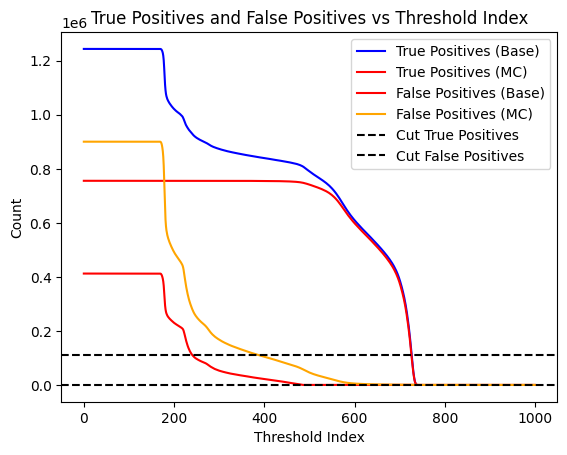

In [10]:
plt.plot(N_mc_fit[0], color='blue', label='True Positives (Base)')
plt.plot(N_mc_truth[0], color='red', label='True Positives (MC)')
plt.plot(N_mc_fit[1], color='red', label='False Positives (Base)')
plt.plot(N_mc_truth[1], color='orange', label='False Positives (MC)')
plt.axhline(N_cut_fit_data[0], color='black', linestyle='--', label='Cut True Positives')
plt.axhline(N_cut_fit_data[1], color='black', linestyle='--', label='Cut False Positives')
plt.xlabel('Threshold Index')
plt.ylabel('Count')
plt.title('True Positives and False Positives vs Threshold Index')
plt.legend()
plt.show()

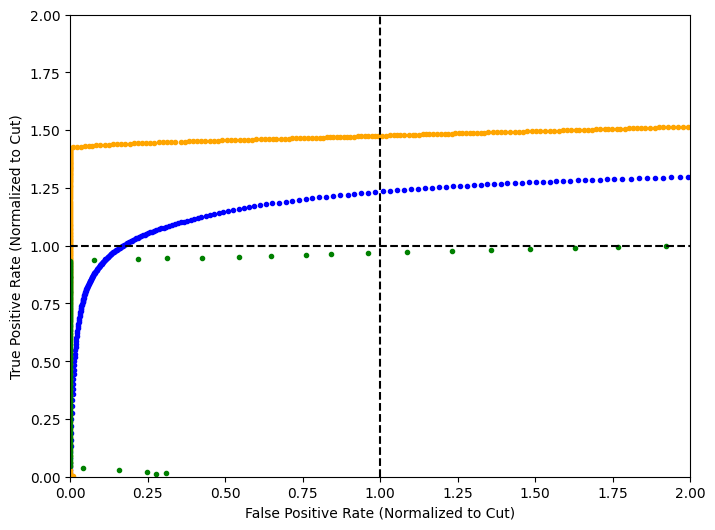

In [17]:
plt.figure(figsize=(8, 6))
plt.plot(N_mc_truth[1]/N_cut_truth[1], N_mc_truth[0]/N_cut_truth[0], '.', color='blue', label='ML Model')
plt.plot(N_mc_fit[1]/(N_cut_fit_mc[1]+20000), N_mc_fit[0]/(N_cut_fit_mc[0]-20000), '.', color='orange', label='MC Fit')
plt.plot(N_data_fit[1]/N_cut_fit_data[1], N_data_fit[0]/N_cut_fit_data[0], '.', color='green', label='Data Fit')
plt.axhline(1, color='black', linestyle='--', label='Cut True Positive Rate')
plt.axvline(1, color='black', linestyle='--', label='Cut False Positive Rate')
plt.xlabel('False Positive Rate (Normalized to Cut)')
plt.ylabel('True Positive Rate (Normalized to Cut)')
plt.xlim(0.0, 2.0)
plt.ylim(0.0, 2.0)
plt.show()

In [13]:
means_dataset = dataset_classes.H5EgammaDataset(
    h5_files_egam[:3],
    exclude_features=["truth"],
    exclude_fields={"egammas": ["truthOrigin", "truthType", "passid_VeryLoose", "passid_Loose", "passid_Medium", "passid_Tight"]},
    y_source = "egammas",
    y_field = ["truthOrigin"],
    valid_fields = {"egammas": ["truthOrigin"]}
)
means, stds = misc_functions.compute_mean_std(means_dataset, sample_size=200_000, batch_size = 4096)
means_dataset.close()

val_dataset = dataset_classes.ZPairDataset(
    h5_files_egam[:3],
    exclude_features=["truth"],
    exclude_fields={"egammas": ["truthOrigin", "truthType", "passid_VeryLoose", "passid_Loose", "passid_Medium", "passid_Tight"]},
    y_source = "egammas",
    y_field = ["truthOrigin", "passid_Tight", "passid_Medium"],
    valid_fields = {"egammas": ["truthOrigin", "passid_Tight", "passid_Medium"]}
)

val_loader = DataLoader(val_dataset, batch_size=4096, shuffle=False, num_workers=8, pin_memory=False, prefetch_factor=2, persistent_workers=True)


ps_med = []
ps_tight = []
truth = []
for batch in val_loader:
    _, _, _, target, _ = batch
    truth.append(target[:, :, 0])
    ps_tight.append(target[:, :, 1])
    ps_med.append(target[:, :, 2])

ps_med = np.concatenate(ps_med, axis=0)
ps_tight = np.concatenate(ps_tight, axis=0)
truth = np.concatenate(truth, axis=0) == 13
truth = truth.reshape(-1, 2)
truth = truth[:, 0] * truth[:, 1]
ps_med = ps_med.reshape(-1, 2)
ps_med = ps_med[:, 0] * ps_med[:, 1]
ps_tight = ps_tight.reshape(-1, 2)
ps_tight = ps_tight[:, 0] * ps_tight[:, 1]
predictions = model_training.predict(models["origin"], val_loader, device='cpu', means=means, stds=stds)

Prediction completed                                                                                                                                                                                                                                                                                        


In [14]:
cut_labels = (ps_med > 0.5)
cut_true_positives = truth * cut_labels
#cut_false_negatives = targets * (1 - cut_labels)
#cut_true_negatives = (1 - targets) * (1 - cut_labels)
cut_false_positives = (1 - truth) * cut_labels
N_tp_cut = cut_true_positives.sum()
N_tn_cut = cut_false_positives.sum()
    

Num = 500
N_tp = np.zeros(Num)
N_tn = np.zeros(Num)
for i in range(Num):
    predicted_labels = (predictions > -10 + 20*i/Num).astype(bool)
    true_positives = truth * predicted_labels
    #false_negatives = targets * (1 - predicted_labels)
    #true_negatives = (1 - targets) * (1 - predicted_labels)
    false_positives = (1 - truth) * predicted_labels
    N_tp[i] = true_positives.sum()
    N_tn[i] = false_positives.sum()

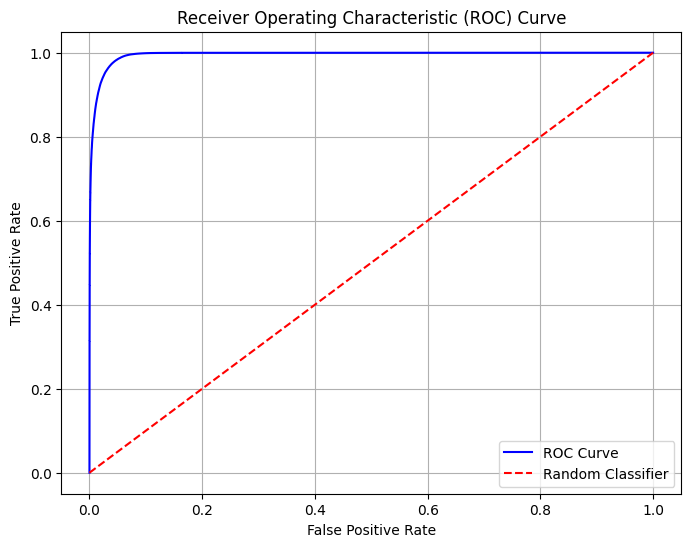

In [15]:
roc_curve_data = roc_curve(truth, predictions)
plt.figure(figsize=(8, 6))
plt.plot(roc_curve_data[0], roc_curve_data[1], color='blue', label='ROC Curve')
plt.plot([0, 1], [0, 1], color='red', linestyle='--', label='Random Classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend()
plt.grid()


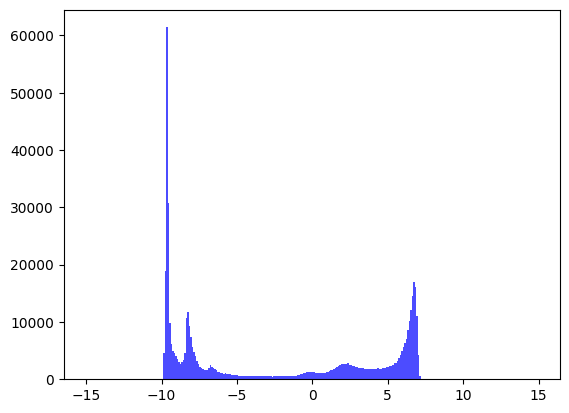

In [16]:
plt.hist(predictions, bins=np.arange(-15, 15, 0.1), alpha=0.7, label='Predictions', color='blue')
plt.show()

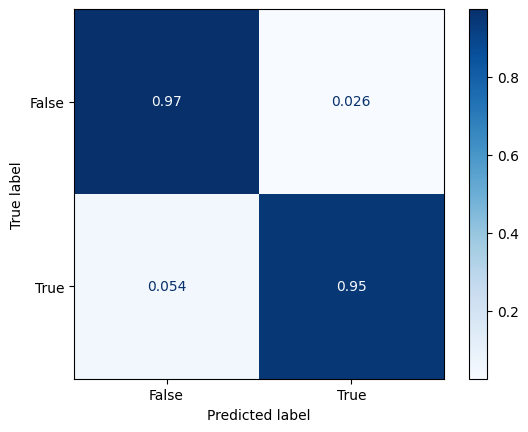

In [17]:
cm = confusion_matrix(truth, predictions > 1.2, normalize='true')
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[False, True])
disp.plot(cmap=plt.cm.Blues)